In [1]:
import pandas as pd
import numpy as np
import soccerdata as sd
import matplotlib.pyplot as plt
from mplsoccer import Pitch, Sbopen


[10/20/26 14:08:49] INFO     No custom team name replacements found. You can configure these in       ]8;id=9486708;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py\_config.py]8;;\:]8;id=9486709;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py#91\91]8;;\
                             C:\Users\elvin\soccerdata\config\teamname_replacements.json.                          

                    INFO     No custom league dict found. You can configure additional leagues in    ]8;id=9486715;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py\_config.py]8;;\:]8;id=9486716;file://c:\Users\elvin\anaconda3\envs\myenv\lib\site-packages\soccerdata\_config.py#189\189]8;;\
                             C:\Users\elvin\soccerdata\config\league_dict.json.                                    

In [2]:
pd.read_json(r'C:\Users\elvin\Documents\Projects\Football\events\Wyscout\matches\matches_World_Cup.json')

,status,roundId,gameweek,teamsData,seasonId,dateutc,winner,venue,wyId,label,date,groupName,referees,duration,competitionId
0,Played,4165368,0,"{'9598': {'scoreET': 0, 'coachId': 122788, 'si...",10078,2018-07-15 15:00:00,4418,Olimpiyskiy stadion Luzhniki,2058017,"France - Croatia, 4 - 2",2018-07-15 17:00:00-02:00,,"[{'refereeId': 378051, 'role': 'referee'}, {'r...",Regular,28
1,Played,4165367,0,"{'2413': {'scoreET': 0, 'coachId': 276858, 'si...",10078,2018-07-14 14:00:00,5629,Stadion Krestovskyi,2058016,"Belgium - England, 2 - 0",2018-07-14 16:00:00-02:00,,"[{'refereeId': 380599, 'role': 'referee'}, {'r...",Regular,28
2,Played,4165366,0,"{'2413': {'scoreET': 1, 'coachId': 276858, 'si...",10078,2018-07-11 18:00:00,9598,Olimpiyskiy stadion Luzhniki,2058015,"Croatia - England, 2 - 1 (E)",2018-07-11 20:00:00-02:00,,"[{'refereeId': 384995, 'role': 'referee'}, {'r...",ExtraTime,28
3,Played,4165366,0,"{'5629': {'scoreET': 0, 'coachId': 8605, 'side...",10078,2018-07-10 18:00:00,4418,Stadion Krestovskyi,2058014,"France - Belgium, 1 - 0",2018-07-10 20:00:00-02:00,,"[{'refereeId': 378232, 'role': 'referee'}, {'r...",Regular,28
4,Played,4165365,0,"{'14358': {'scoreET': 2, 'coachId': 264893, 's...",10078,2018-07-07 18:00:00,9598,Olimpiyskiy Stadion Fisht,2058012,"Russia - Croatia, 2 - 2 (P)",2018-07-07 20:00:00-02:00,,"[{'refereeId': 378204, 'role': 'referee'}, {'r...",Penalties,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,Played,4165363,1,"{'8493': {'scoreET': 0, 'coachId': 134090, 'si...",10078,2018-06-16 10:00:00,4418,Kazan' Arena,2057966,"France - Australia, 2 - 1",2018-06-16 12:00:00-02:00,Group C,"[{'refereeId': 378232, 'role': 'referee'}, {'r...",Regular,28
60,Played,4165363,1,"{'9905': {'scoreET': 0, 'coachId': 137521, 'si...",10078,2018-06-15 18:00:00,0,Olimpiyskiy Stadion Fisht,2057960,"Portugal - Spain, 3 - 3",2018-06-15 20:00:00-02:00,Group B,"[{'refereeId': 377206, 'role': 'referee'}, {'r...",Regular,28
61,Played,4165363,1,"{'10840': {'scoreET': 0, 'coachId': 136612, 's...",10078,2018-06-15 15:00:00,10840,Stadion Krestovskyi,2057961,"Morocco - Iran, 0 - 1",2018-06-15 17:00:00-02:00,Group B,"[{'refereeId': 384995, 'role': 'referee'}, {'r...",Regular,28
62,Played,4165363,1,"{'16129': {'scoreET': 0, 'coachId': 33204, 'si...",10078,2018-06-15 12:00:00,15670,Stadion Central'nyj,2057955,"Egypt - Uruguay, 0 - 1",2018-06-15 14:00:00-02:00,Group A,"[{'refereeId': 377215, 'role': 'referee'}, {'r...",Regular,28


In [3]:
#world cup wyID -> 28
#2018 world cup. I want to see the last 3 French matches before the final
#wyID -> 2058014 (Belgium), 2058010(Uruguay), 2058003(Argentina) .............. 2058017(Croatia - final)
#the goal is to see if I can find any patterns in the 3 knockout games to see if I could predict how they would play in the final against Croatia. I want to see if I can find any patterns in the 3 knockout games to see if I could predict how they would play in the final against Croatia.
#france team id -> 4418

In [4]:
wc_events = pd.read_json(r'C:\Users\elvin\Documents\Projects\Football\events\Wyscout\events\events_World_Cup.json')

In [5]:
france_kos = wc_events[(wc_events['matchId'] == 2058014)|(wc_events['matchId'] == 2058010)|(wc_events['matchId'] == 2058003)]

In [6]:
france_kos

,eventId,subEventName,tags,playerId,positions,matchId,eventName,teamId,matchPeriod,eventSec,subEventId,id
76081,8,Simple pass,[{'id': 1801}],3682,"[{'y': 50, 'x': 50}, {'y': 69, 'x': 33}]",2058003,Pass,4418,1H,1.302651,85,261065118
76082,8,High pass,[{'id': 1801}],3309,"[{'y': 69, 'x': 33}, {'y': 74, 'x': 70}]",2058003,Pass,4418,1H,5.377012,83,261065119
76083,1,Air duel,"[{'id': 701}, {'id': 1802}]",26010,"[{'y': 74, 'x': 70}, {'y': 76, 'x': 69}]",2058003,Duel,4418,1H,7.507633,10,261065120
76084,1,Air duel,"[{'id': 703}, {'id': 1801}]",86722,"[{'y': 26, 'x': 30}, {'y': 24, 'x': 31}]",2058003,Duel,12274,1H,8.162743,10,261065122
76085,2,Foul,[],26010,"[{'y': 76, 'x': 69}, {'y': 74, 'x': 70}]",2058003,Foul,4418,1H,8.823650,20,261065121
...,...,...,...,...,...,...,...,...,...,...,...,...
96687,9,Reflexes,"[{'id': 1202}, {'id': 1801}]",3429,"[{'y': 100, 'x': 100}, {'y': 65, 'x': 13}]",2058014,Save attempt,5629,2H,3019.159244,90,262919764
96688,3,Corner,[{'id': 1801}],353833,"[{'y': 100, 'x': 100}, {'y': 99, 'x': 97}]",2058014,Free Kick,4418,2H,3055.990566,30,262919735
96689,1,Ground attacking duel,"[{'id': 701}, {'id': 1802}]",7936,"[{'y': 99, 'x': 97}, {'y': 97, 'x': 96}]",2058014,Duel,4418,2H,3058.502171,11,262919737
96690,1,Ground defending duel,"[{'id': 703}, {'id': 1801}]",134769,"[{'y': 1, 'x': 3}, {'y': 3, 'x': 4}]",2058014,Duel,5629,2H,3059.808444,12,262919766


In [7]:
#now the question becomes, what do I look for that tells me what their style of play was.
#areas they had the ball in before they took shots.
#first thing I'm going to do is look at France's passing networks in the 4 knockout games and compare them with their opponents passing networks


In [8]:
#for passing networks, we look for successful passes that were made by a team until the first sub
france_kos.subEventName.unique()

array(['Simple pass', 'High pass', 'Air duel', 'Foul', 'Free Kick',
       'Ground attacking duel', 'Ground defending duel', 'Throw in',
       'Touch', 'Ground loose ball duel', 'Free kick cross', 'Clearance',
       'Head pass', 'Smart pass', 'Cross', 'Goal kick', 'Launch',
       'Acceleration', 'Free kick shot', 'Penalty', 'Reflexes', 'Corner',
       'Shot', 'Hand pass', 'Save attempt', 'Out of game foul', '',
       'Goalkeeper leaving line', 'Hand foul', 'Time lost foul'],
      dtype=object)

In [9]:
wc_matches = pd.read_json(r'C:\Users\elvin\Documents\Projects\Football\events\Wyscout\matches\matches_World_Cup.json')

In [10]:
#dict_keys(['scoreET', 'coachId', 'side', 'teamId', 'score', 'scoreP', 'hasFormation', 'formation', 'scoreHT'])
wc_matches[(wc_matches['wyId']== 2058014)|(wc_matches['wyId']== 2058010)|(wc_matches['wyId']== 2058003)]['teamsData'][3]['4418']['formation']['substitutions']


[{'playerIn': 8200, 'assists': '0', 'playerOut': 26010, 'minute': 85},
 {'playerIn': 209091, 'assists': '0', 'playerOut': 25437, 'minute': 86}]

In [11]:
sub_min = {}
for mid in france_kos.matchId.unique():
    first_sub = wc_matches[wc_matches['wyId']==mid]['teamsData'].iloc[0]['4418']['formation']['substitutions'][0]['minute']
    sub_min[mid] = first_sub
    

In [12]:
players = pd.read_json(r'C:\Users\elvin\Documents\Projects\Football\events\Wyscout\players.json',encoding='unicode-escape')
players = players[['wyId','shortName']]

In [18]:
sub_min

{2058003: 75, 2058010: 80, 2058014: 85}

In [19]:
match_id = 2058003
sub_filter = sub_min[match_id]


df = france_kos.copy()
df['pass_recipientId'] = df['playerId'].shift(-1)
passes = df[df['eventName']=='Pass'].copy()
passes['x'] = passes.positions.apply(lambda cell: (cell[0]['x']))
passes['y'] = passes.positions.apply(lambda cell: (cell[0]['y']))
passes['end_x'] = passes.positions.apply(lambda cell: (cell[1]['x']))
passes['end_y'] = passes.positions.apply(lambda cell: (cell[1]['y']))

accurate_passes = passes.loc[passes.apply(lambda x:{'id':1801}in x.tags, axis=1)]

accurate_passes = accurate_passes.merge(players.rename(columns={'wyId':'playerId','shortName':'player'}),how='left',on='playerId')
accurate_passes = accurate_passes.merge(players.rename(columns={'wyId':'pass_recipientId', 'shortName':'pass_recipient'}),how='left',on='pass_recipientId')
accurate_passes = accurate_passes[['player','x','y','end_x','end_y','pass_recipient','subEventName','teamId','eventSec','matchPeriod','matchId']]

accurate_passes

france_mask = (accurate_passes.teamId==4418)&(accurate_passes.eventSec < 1800)*(accurate_passes.matchPeriod=='2H')&(accurate_passes.matchId==match_id)
french_passes = accurate_passes.loc[france_mask]

In [20]:
french_passes

,player,x,y,end_x,end_y,pass_recipient,subEventName,teamId,eventSec,matchPeriod,matchId
416,N. Kanté,36,54,48,88,P. Pogba,Simple pass,4418,226.641055,2H,2058003
417,P. Pogba,48,88,64,98,K. Mbappé,Simple pass,4418,229.358272,2H,2058003
418,N. Kanté,67,92,63,81,R. Varane,Simple pass,4418,310.086384,2H,2058003
419,R. Varane,63,81,69,48,S. Umtiti,Simple pass,4418,311.949714,2H,2058003
420,S. Umtiti,69,48,89,4,L. Hernández,High pass,4418,314.234724,2H,2058003
...,...,...,...,...,...,...,...,...,...,...,...
577,S. Umtiti,31,24,45,35,B. Matuidi,Simple pass,4418,1730.641156,2H,2058003
578,B. Matuidi,45,35,41,50,P. Pogba,Simple pass,4418,1732.232773,2H,2058003
580,H. Lloris,9,50,14,30,S. Umtiti,Simple pass,4418,1751.133908,2H,2058003
581,S. Umtiti,14,30,38,19,A. Griezmann,High pass,4418,1753.705538,2H,2058003


In [ ]:
player_plots = pd.DataFrame()

for i, name in enumerate(french_passes['player'].unique()):
    passx = french_passes[french_passes['player']==name]['x'].to_numpy()
    recx = french_passes[french_passes['pass_recipient']==name]['end_x'].to_numpy()
    passy = french_passes[french_passes['player']==name]['y'].to_numpy()
    recy = french_passes[french_passes['player']==name]['end_y'].to_numpy()
    player_plots.at[i,"player"] = name
    player_plots.at[i,"x"] = np.mean(np.concatenate([passx,recx]))
    player_plots.at[i,"y"] = np.mean(np.concatenate([passy,recy]))

    player_plots.at[i,'no'] = french_passes[french_passes['player']==name].count().iloc[0]

player_plots['marker_size'] = (player_plots['no']/player_plots['no'].max()*1500)

player_plots

,player,x,y,no,marker_size
0,N. Kanté,42.384615,48.529412,17.0,1500.000000
1,P. Pogba,57.444444,67.562500,8.0,705.882353
2,R. Varane,39.285714,73.533333,15.0,1323.529412
3,S. Umtiti,36.592593,33.625000,16.0,1411.764706
4,B. Pavard,55.181818,89.833333,6.0,529.411765
5,B. Matuidi,56.280000,43.708333,12.0,1058.823529
6,A. Griezmann,58.538462,36.200000,5.0,441.176471
7,K. Mbappé,59.117647,78.071429,7.0,617.647059
8,H. Lloris,10.100000,51.333333,6.0,529.411765
9,L. Hernández,62.833333,26.100000,5.0,441.176471


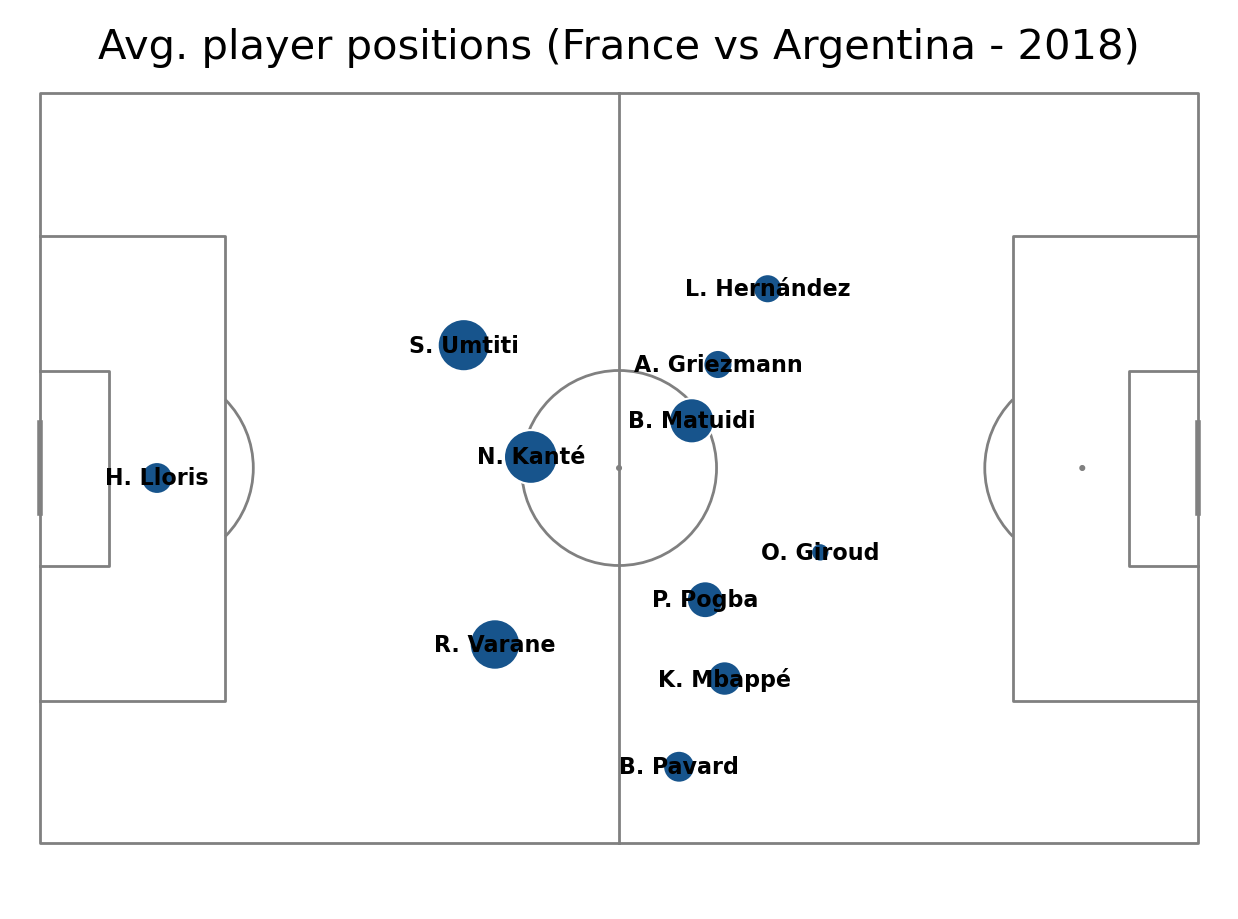

In [ ]:
pitch = Pitch(line_color='grey',pitch_type='wyscout')
fig, ax = pitch.grid(grid_height=0.9, title_height=0.06, axis=False,
                     endnote_height=0.04, title_space=0, endnote_space=0)

pitch.scatter(player_plots.x,player_plots.y, s=player_plots.marker_size, color='#17548C',
              edgecolors='white', linewidth=1.5, ax=ax['pitch'],zorder=3)

for i, row in player_plots.iterrows():
    pitch.annotate(row.player,xy=(row.x,row.y),c='black', va='center', ha='center', weight='bold',
                   size=16, ax=ax['pitch'],zorder=4)

fig.suptitle("Avg. player passing position (France vs Argentina - 2018)", fontsize=30)
plt.show()

In [23]:
french_passes['pair_key'] = french_passes.apply(lambda x: '_'.join(sorted([x['player'], x['pass_recipient']])),axis=1)
lines_df = french_passes.groupby(['pair_key']).x.count().reset_index()
lines_df.rename({'x':'pass_count'}, axis='columns', inplace=True)
lines_df = lines_df[lines_df['pass_count']>2]

[20/10/2026 16:56:25] WARNING  C:\Users\elvin\AppData\Local\Temp\ipykernel_12056\2934860298.py:1:   ]8;id=9486723;file://c:\Users\elvin\anaconda3\envs\myenv\lib\warnings.py\warnings.py]8;;\:]8;id=9486724;file://c:\Users\elvin\anaconda3\envs\myenv\lib\warnings.py#109\109]8;;\
                               SettingWithCopyWarning:                                                             
                               A value is trying to be set on a copy of a slice from a DataFrame.                  
                               Try using .loc = value instead                                                      
                                                                                                                   
                               See the caveats in the documentation:                                               
                               https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.htm                
                               l#returning-a-view-versus-a-copy                                                    
                                 french_passes['pair_key'] = french_passes.apply(lambda x:                         
                               '_'.join(sorted([x['player'], x['pass_recipient']])),axis=1)                        
                                                                                                                   

In [24]:
lines_df

,pair_key,pass_count
0,A. Griezmann_B. Matuidi,3
9,B. Matuidi_K. Mbappé,4
11,B. Matuidi_N. Kanté,4
13,B. Matuidi_P. Pogba,3
15,B. Matuidi_S. Umtiti,5
20,B. Pavard_R. Varane,6
24,H. Lloris_S. Umtiti,4
27,K. Mbappé_P. Pogba,4
28,K. Mbappé_R. Varane,4
33,L. Hernández_S. Umtiti,4
